In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
Clean_Data_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data")
Table_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables")
Chart_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts")

print("Clean data:", Clean_Data_Path)
print("Output tables:", Table_Path)
print("Output charts:", Chart_Path)

Clean data: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data
Output tables: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables
Output charts: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts


In [3]:
orders = pd.read_csv(
    Clean_Data_Path / "orders_clean.csv"
)

order_items = pd.read_csv(
    Clean_Data_Path / "order_items_clean.csv"
)

products = pd.read_csv(
    Clean_Data_Path / "products_clean.csv"
)

sellers = pd.read_csv(
    Clean_Data_Path / "sellers_clean.csv"
)

customers = pd.read_csv(
    Clean_Data_Path / "customers_clean.csv"
)

category_translation = pd.read_csv(
    Clean_Data_Path / "category_translation_clean.csv"
)

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)
print("Customers:", customers.shape)
print("Category translation:", category_translation.shape)

Orders: (96461, 8)
Order items: (112650, 7)
Products: (32951, 9)
Sellers: (3095, 4)
Customers: (99441, 5)
Category translation: (71, 2)


In [4]:
#product sales dataset
product_sales = order_items.merge(
    products[
        [
            "product_id",
            "product_category_name"
        ]
    ],
    on="product_id",
    how="left"
)

product_sales = product_sales.merge(
    category_translation[
        [
            "product_category_name",
            "product_category_name_english"
        ]
    ],
    on="product_category_name",
    how="left"
)

product_sales["category"] = (
    product_sales["product_category_name_english"]
    .fillna(product_sales["product_category_name"])
    .fillna("Unknown")
)

print(product_sales.shape)
product_sales.head()

(112650, 10)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english,category
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools,garden_tools


In [5]:
#Category intelligence
category_performance = (
    product_sales
    .groupby("category")
    .agg(
        revenue=("price", "sum"),
        freight=("freight_value", "sum"),
        units_sold=("order_item_id", "count"),
        unique_orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique")
    )
    .reset_index()
)

category_performance["average_selling_price"] = (
    category_performance["revenue"]
    / category_performance["units_sold"]
)

category_performance["freight_to_revenue_percent"] = (
    category_performance["freight"]
    / category_performance["revenue"]
    * 100
)

category_performance = category_performance.sort_values(
    "revenue",
    ascending=False
)

category_performance.head(10)

,category,revenue,freight,units_sold,unique_orders,unique_products,average_selling_price,freight_to_revenue_percent
43,health_beauty,1258681.34,182566.73,9670,8836,2444,130.163531,14.504603
73,watches_gifts,1205005.68,100535.93,5991,5624,1329,201.135984,8.343191
7,bed_bath_table,1036988.68,204693.04,11115,9417,3029,93.296327,19.739178
67,sports_leisure,988048.97,168607.51,8641,7720,2867,114.344285,17.064692
15,computers_accessories,911954.32,147318.08,7827,6689,1639,116.513903,16.154107
39,furniture_decor,729762.49,172749.30,8334,6449,2657,87.564494,23.671989
20,cool_stuff,635290.85,84039.10,3796,3632,789,167.357969,13.228445
49,housewares,632248.66,146149.11,6964,5884,2335,90.788148,23.115764
5,auto,592720.11,92664.21,4235,3897,1900,139.957523,15.633721
42,garden_tools,485256.46,98962.75,4347,3518,753,111.630196,20.393907


In [6]:
category_performance["revenue_share_percent"] = (
    category_performance["revenue"]
    / category_performance["revenue"].sum()
    * 100
)

category_performance.head(10)

,category,revenue,freight,units_sold,unique_orders,unique_products,average_selling_price,freight_to_revenue_percent,revenue_share_percent
43,health_beauty,1258681.34,182566.73,9670,8836,2444,130.163531,14.504603,9.260700
73,watches_gifts,1205005.68,100535.93,5991,5624,1329,201.135984,8.343191,8.865783
7,bed_bath_table,1036988.68,204693.04,11115,9417,3029,93.296327,19.739178,7.629605
67,sports_leisure,988048.97,168607.51,8641,7720,2867,114.344285,17.064692,7.269533
15,computers_accessories,911954.32,147318.08,7827,6689,1639,116.513903,16.154107,6.709669
39,furniture_decor,729762.49,172749.30,8334,6449,2657,87.564494,23.671989,5.369200
20,cool_stuff,635290.85,84039.10,3796,3632,789,167.357969,13.228445,4.674128
49,housewares,632248.66,146149.11,6964,5884,2335,90.788148,23.115764,4.651745
5,auto,592720.11,92664.21,4235,3897,1900,139.957523,15.633721,4.360916
42,garden_tools,485256.46,98962.75,4347,3518,753,111.630196,20.393907,3.570256


In [8]:
category_performance.to_csv(
    Table_Path / "category_performance.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "category_performance.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\category_performance.csv


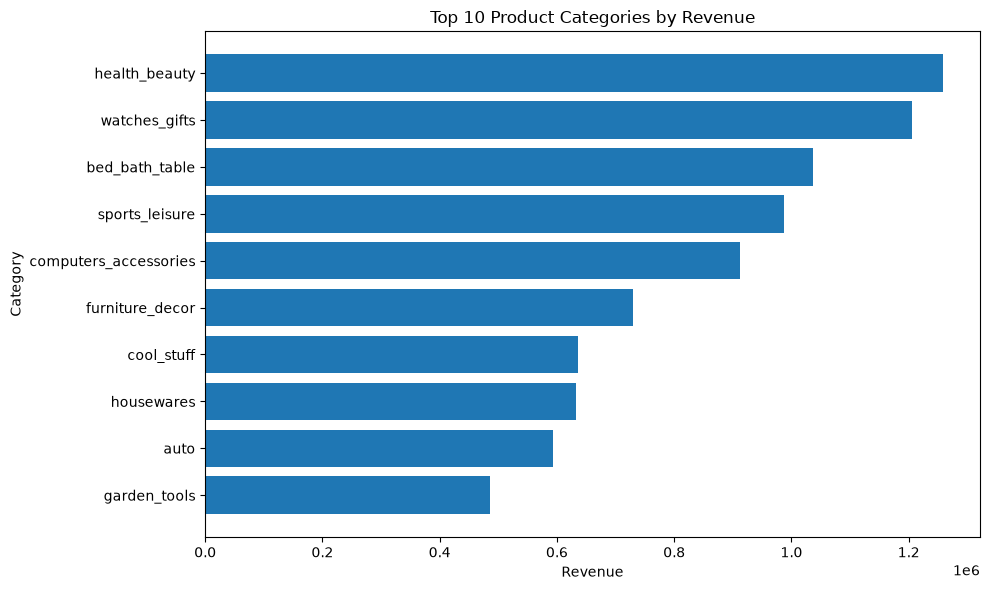

In [10]:
#op categories visualization
top_categories = (
    category_performance
    .head(10)
    .sort_values("revenue")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["category"],
    top_categories["revenue"]
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Category")

plt.tight_layout()

plt.savefig(
    Chart_Path / "18_top_categories_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
#Seller performance
seller_performance = (
    order_items
    .groupby("seller_id")
    .agg(
        revenue=("price", "sum"),
        freight=("freight_value", "sum"),
        units_sold=("order_item_id", "count"),
        unique_orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique")
    )
    .reset_index()
)

seller_performance["average_order_item_value"] = (
    seller_performance["revenue"]
    / seller_performance["units_sold"]
)

seller_performance["freight_to_revenue_percent"] = (
    seller_performance["freight"]
    / seller_performance["revenue"]
    * 100
)

seller_performance = seller_performance.sort_values(
    "revenue",
    ascending=False
)

seller_performance.head(10)

,seller_id,revenue,freight,units_sold,unique_orders,unique_products,average_order_item_value,freight_to_revenue_percent
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,20168.07,1156,1132,95,198.505735,8.788878
1013,53243585a1d6dc2643021fd1853d8905,222776.05,13080.63,410,358,23,543.356220,5.871650
881,4a3ca9315b744ce9f8e9374361493884,200472.92,35067.04,1987,1806,399,100.892260,17.492158
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,10042.70,586,585,289,331.129744,5.175528
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89,51612.55,1364,982,198,137.774113,27.464603
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87,6322.18,340,336,186,518.917265,3.583355
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,24955.75,1551,1314,222,103.311779,15.574316
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53,20902.85,1171,1160,149,121.046567,14.746744
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,33892.14,1428,915,154,97.316912,24.388353
1824,955fee9216a65b617aa5c0531780ce60,135171.70,25430.98,1499,1287,104,90.174583,18.813835


In [12]:
#Add seller geography
seller_performance = seller_performance.merge(
    sellers[
        [
            "seller_id",
            "seller_city",
            "seller_state"
        ]
    ],
    on="seller_id",
    how="left"
)

seller_performance.head()

,seller_id,revenue,freight,units_sold,unique_orders,unique_products,average_order_item_value,freight_to_revenue_percent,seller_city,seller_state
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,20168.07,1156,1132,95,198.505735,8.788878,guariba,SP
1,53243585a1d6dc2643021fd1853d8905,222776.05,13080.63,410,358,23,543.356220,5.871650,lauro de freitas,BA
2,4a3ca9315b744ce9f8e9374361493884,200472.92,35067.04,1987,1806,399,100.892260,17.492158,ibitinga,SP
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,10042.70,586,585,289,331.129744,5.175528,sumare,SP
4,7c67e1448b00f6e969d365cea6b010ab,187923.89,51612.55,1364,982,198,137.774113,27.464603,itaquaquecetuba,SP


In [13]:
top_sellers = (
    seller_performance[
        seller_performance["unique_orders"] >= 20
    ]
    .head(20)
)

top_sellers

,seller_id,revenue,freight,units_sold,unique_orders,unique_products,average_order_item_value,freight_to_revenue_percent,seller_city,seller_state
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,20168.07,1156,1132,95,198.505735,8.788878,guariba,SP
1,53243585a1d6dc2643021fd1853d8905,222776.05,13080.63,410,358,23,543.356220,5.871650,lauro de freitas,BA
2,4a3ca9315b744ce9f8e9374361493884,200472.92,35067.04,1987,1806,399,100.892260,17.492158,ibitinga,SP
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,10042.70,586,585,289,331.129744,5.175528,sumare,SP
4,7c67e1448b00f6e969d365cea6b010ab,187923.89,51612.55,1364,982,198,137.774113,27.464603,itaquaquecetuba,SP
5,7e93a43ef30c4f03f38b393420bc753a,176431.87,6322.18,340,336,186,518.917265,3.583355,barueri,SP
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,24955.75,1551,1314,222,103.311779,15.574316,piracicaba,SP
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53,20902.85,1171,1160,149,121.046567,14.746744,sao paulo,SP
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,33892.14,1428,915,154,97.316912,24.388353,sao paulo,SP
9,955fee9216a65b617aa5c0531780ce60,135171.70,25430.98,1499,1287,104,90.174583,18.813835,sao paulo,SP


In [14]:
seller_performance.to_csv(
    Table_Path / "seller_performance.csv",
    index=False
)

top_sellers.to_csv(
    Table_Path / "top_sellers_20_orders_min.csv",
    index=False
)

print("Seller tables saved.")

Seller tables saved.


In [15]:
#Customer geographic intelligence
customer_features = pd.read_csv(
    Table_Path / "customer_feature_table.csv"
)

customer_features.head()

,customer_unique_id,order_count,total_revenue,total_freight,total_spend,total_items,first_purchase,last_purchase,customer_state,customer_city,...,total_payment_value,average_installments,recency_days,frequency,monetary_value,recency_score,frequency_score,monetary_score,rfm_score,customer_segment
0,b38211bd797f4fdd81a98b9d1754b606,1,0.85,18.23,19.08,1,2018-04-24 20:15:21,2018-04-24 20:15:21,RJ,duque de caxias,...,19.08,1.0,126,1,0.85,4,4,1,441,Loyal Customers
1,d80730c15c647bc8f2ad77c908ba5ca9,1,0.85,18.23,19.08,1,2018-04-24 11:01:06,2018-04-24 11:01:06,SP,hortolandia,...,19.08,1.0,127,1,0.85,4,5,1,451,Loyal Customers
2,317cfc692e3f86c45c95697c61c853a6,1,2.20,7.39,9.59,1,2018-08-25 21:20:50,2018-08-25 21:20:50,SP,paulinia,...,9.59,1.0,3,1,2.20,5,1,1,511,Other
3,bd06ce0e06ad77a7f681f1a4960a3cc6,1,2.29,7.78,10.07,1,2017-09-13 19:13:20,2017-09-13 19:13:20,SP,sao paulo,...,10.07,1.0,349,1,2.29,2,4,1,241,At Risk
4,cf3839da0d9492ad151690b65f45d800,1,2.99,11.85,14.84,1,2018-02-02 00:01:31,2018-02-02 00:01:31,SP,jandira,...,14.84,1.0,208,1,2.99,3,4,1,341,Loyal Customers


In [16]:
#State-level customer demand
state_demand = (
    customer_features
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "count"),
        orders=("order_count", "sum"),
        revenue=("total_revenue", "sum"),
        average_customer_revenue=("total_revenue", "mean")
    )
    .reset_index()
)

state_demand["revenue_per_order"] = (
    state_demand["revenue"]
    / state_demand["orders"]
)

state_demand = state_demand.sort_values(
    "revenue",
    ascending=False
)

state_demand.head(10)

,customer_state,customers,orders,revenue,average_customer_revenue,revenue_per_order
25,SP,39139,40495,5067100.51,129.464230,125.129041
18,RJ,11914,12350,1759696.75,147.699912,142.485567
10,MG,10994,11351,1552281.89,141.193550,136.752876
22,RS,5164,5342,728285.48,141.031270,136.331988
17,PR,4768,4925,666158.31,139.714411,135.260571
23,SC,3445,3544,506539.73,147.036206,142.928818
4,BA,3158,3258,493847.55,156.379845,151.579972
6,DF,2017,2079,295897.11,146.701591,142.326652
8,GO,1894,1960,283721.59,149.800206,144.755913
7,ES,1928,1996,268733.35,139.384518,134.635947


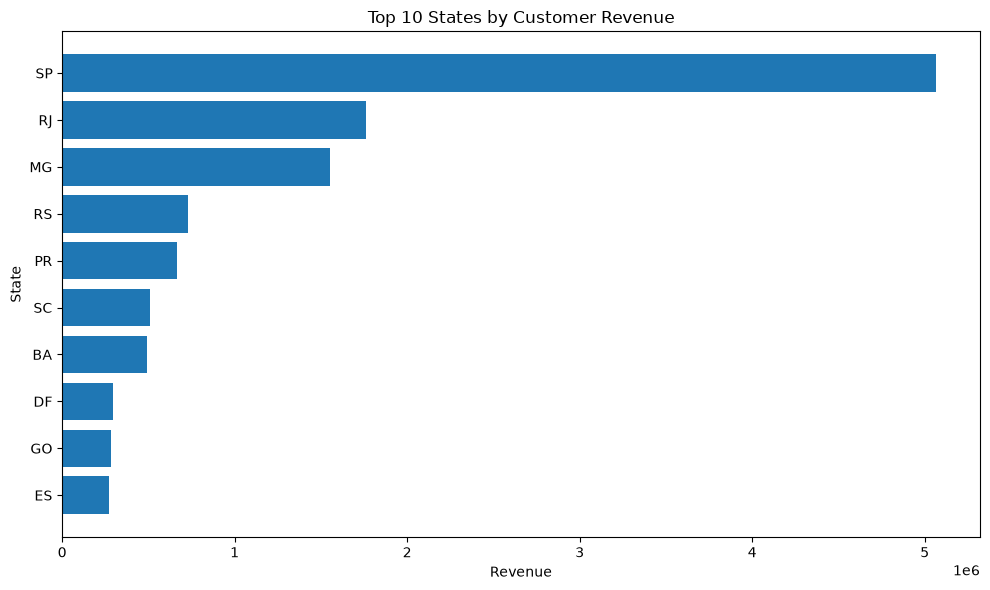

In [18]:
#State demand visualization
top_states = (
    state_demand
    .head(10)
    .sort_values("revenue")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_states["customer_state"],
    top_states["revenue"]
)

plt.title("Top 10 States by Customer Revenue")
plt.xlabel("Revenue")
plt.ylabel("State")

plt.tight_layout()

plt.savefig(
    Chart_Path / "19_top_states_customer_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
state_demand.to_csv(
    Table_Path / "state_demand_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "state_demand_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\state_demand_summary.csv


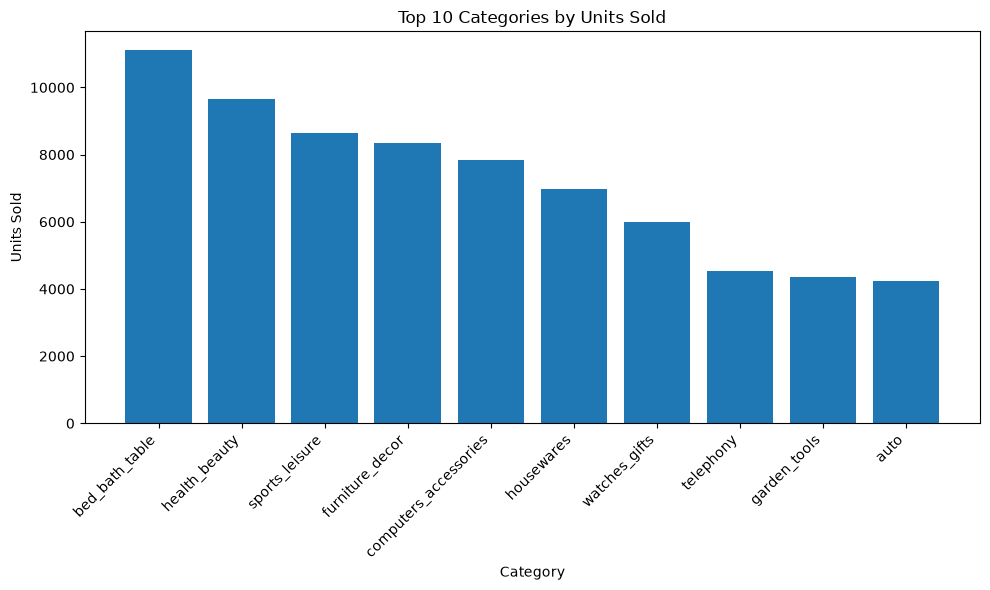

In [20]:
#Product demand vs revenue
category_volume = (
    category_performance
    .sort_values(
        "units_sold",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.bar(
    category_volume["category"],
    category_volume["units_sold"]
)

plt.title("Top 10 Categories by Units Sold")
plt.xlabel("Category")
plt.ylabel("Units Sold")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    Chart_Path / "20_top_categories_units.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
#Category revenue vs volume
category_value_volume = (
    category_performance[
        [
            "category",
            "revenue",
            "units_sold",
            "unique_orders",
            "average_selling_price",
            "revenue_share_percent"
        ]
    ]
    .sort_values(
        "revenue",
        ascending=False
    )
)

category_value_volume.head(15)

,category,revenue,units_sold,unique_orders,average_selling_price,revenue_share_percent
43,health_beauty,1258681.34,9670,8836,130.163531,9.260700
73,watches_gifts,1205005.68,5991,5624,201.135984,8.865783
7,bed_bath_table,1036988.68,11115,9417,93.296327,7.629605
67,sports_leisure,988048.97,8641,7720,114.344285,7.269533
15,computers_accessories,911954.32,7827,6689,116.513903,6.709669
39,furniture_decor,729762.49,8334,6449,87.564494,5.369200
20,cool_stuff,635290.85,3796,3632,167.357969,4.674128
49,housewares,632248.66,6964,5884,90.788148,4.651745
5,auto,592720.11,4235,3897,139.957523,4.360916
42,garden_tools,485256.46,4347,3518,111.630196,3.570256


In [22]:
category_value_volume.to_csv(
    Table_Path / "category_value_volume_analysis.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "category_value_volume_analysis.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\category_value_volume_analysis.csv


In [23]:
#Location + seller summary
seller_state_summary = (
    seller_performance
    .groupby("seller_state")
    .agg(
        sellers=("seller_id", "nunique"),
        revenue=("revenue", "sum"),
        units_sold=("units_sold", "sum"),
        orders=("unique_orders", "sum")
    )
    .reset_index()
    .sort_values(
        "revenue",
        ascending=False
    )
)

seller_state_summary.head(10)

,seller_state,sellers,revenue,units_sold,orders
22,SP,1849,8753396.21,80342,70950
15,PR,349,1261887.21,8671,7717
8,MG,244,1011564.74,8827,7942
16,RJ,171,843984.22,4818,4355
20,SC,190,632426.07,4075,3672
19,RS,129,378559.54,2199,1991
2,BA,19,285561.56,643,569
4,DF,30,97749.48,899,824
13,PE,9,91493.85,448,406
6,GO,40,66399.21,520,463


In [25]:
seller_state_summary.to_csv(
    Table_Path / "seller_state_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "seller_state_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\seller_state_summary.csv


In [26]:
#Final product/location KPI table
product_location_kpis = pd.DataFrame({
    "metric": [
        "Product Categories",
        "Products",
        "Sellers",
        "Top Category Revenue",
        "Top Category Units Sold",
        "Top Customer Revenue State",
        "Top Seller Revenue State"
    ],
    "value": [
        category_performance["category"].nunique(),
        products["product_id"].nunique(),
        sellers["seller_id"].nunique(),
        category_performance.iloc[0]["category"],
        category_performance.sort_values(
            "units_sold",
            ascending=False
        ).iloc[0]["category"],
        state_demand.iloc[0]["customer_state"],
        seller_state_summary.iloc[0]["seller_state"]
    ]
})

product_location_kpis

,metric,value
0,Product Categories,74
1,Products,32951
2,Sellers,3095
3,Top Category Revenue,health_beauty
4,Top Category Units Sold,bed_bath_table
5,Top Customer Revenue State,SP
6,Top Seller Revenue State,SP


In [28]:
product_location_kpis.to_csv(
    Table_Path / "product_location_kpis.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "product_location_kpis.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\product_location_kpis.csv
